# Ames Housing: Data Loading and Cleaning

**Analytical question:** How does above-ground living area affect home sale prices in Ames, Iowa, and does the relationship differ by neighborhood?

This notebook currently covers data loading, validation, a review of potential quality issues, and descriptive statistics. No outliers are removed.

## 1. Import libraries and load the data

The CSV is in the repository’s main folder. The relative path below starts from this notebook’s `analysis/` folder.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

repo_root = Path.cwd()
if not (repo_root / 'AmesHousing-1.csv').exists():
    repo_root = repo_root.parent
data_path = repo_root / 'AmesHousing-1.csv'
df = pd.read_csv(data_path)

print(f'Dataset dimensions: {df.shape[0]:,} rows × {df.shape[1]} columns')
display(df.head())

Dataset dimensions: 2,930 rows × 82 columns


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


## 2. Select and validate analysis variables

Keep only the outcome, predictor, and grouping variable needed for this question. Numeric conversion uses `errors='coerce'`; the next cell counts any values that fail conversion, so they can be distinguished from original missing values. The expected dataset stores both measures as numbers.

In [2]:
analysis_columns = ['Gr Liv Area', 'SalePrice', 'Neighborhood']
analysis_data = df.loc[:, analysis_columns].copy()

numeric_columns = ['Gr Liv Area', 'SalePrice']
conversion_failures = {}
for column in numeric_columns:
    original_nonmissing = analysis_data[column].notna()
    converted = pd.to_numeric(analysis_data[column], errors='coerce')
    conversion_failures[column] = int((original_nonmissing & converted.isna()).sum())
    analysis_data[column] = converted

print('Conversion failures:', conversion_failures)
print('Data types after validation:')
display(analysis_data.dtypes.to_frame('dtype'))
assert all(pd.api.types.is_numeric_dtype(analysis_data[c]) for c in numeric_columns)

Conversion failures: {'Gr Liv Area': 0, 'SalePrice': 0}
Data types after validation:


,dtype
Gr Liv Area,int64
SalePrice,int64
Neighborhood,object


## 3. Check missing values, duplicates, and nonpositive values

Missing values are reported for each selected field. Duplicate checks include fully identical source rows and repeated combinations of the three analysis fields. A repeated combination of area, price, and neighborhood is not automatically a duplicate home: different homes can share those values. Therefore, no rows are dropped based only on these checks. The numeric measures are also checked for zero or negative values, which would be invalid for this analysis.

In [3]:
missing_counts = analysis_data.isna().sum()
full_row_duplicate_count = int(df.duplicated().sum())
selected_combination_duplicate_count = int(analysis_data.duplicated().sum())
nonpositive_counts = (analysis_data[numeric_columns] <= 0).sum()

print('Missing values by selected column:')
display(missing_counts.to_frame('missing_count'))
print(f'Fully duplicated source rows: {full_row_duplicate_count}')
print(f'Repeated combinations of selected fields: {selected_combination_duplicate_count}')
print('Nonpositive values in numeric fields:')
display(nonpositive_counts.to_frame('nonpositive_count'))

Missing values by selected column:


,missing_count
Gr Liv Area,0
SalePrice,0
Neighborhood,0


Fully duplicated source rows: 0
Repeated combinations of selected fields: 20
Nonpositive values in numeric fields:


,nonpositive_count
Gr Liv Area,0
SalePrice,0


## 4. Review unusual values and define the cleaned data

The following cell flags values outside the 1.5×IQR fences for each numeric variable and reports observed minima and maxima. These flags are prompts for review, not proof of data errors. Large homes and high-value sales may be genuine and could influence a fitted relationship, especially a linear model. We retain all rows and do not winsorize or remove outliers.

If selected fields are missing or a numeric field contains a nonpositive value, rows with those conditions are excluded from `cleaned_data` for this analysis. The checks above make each exclusion visible. Repeated combinations of the selected fields are retained because they do not establish that a source record is duplicated.

In [4]:
outlier_review = []
for column in numeric_columns:
    values = analysis_data[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    flagged = (values < lower_fence) | (values > upper_fence)
    outlier_review.append({
        'variable': column, 'minimum': values.min(), 'maximum': values.max(),
        'lower_IQR_fence': lower_fence, 'upper_IQR_fence': upper_fence,
        'outside_fence_count': int(flagged.sum()),
        'outside_fence_percent': 100 * flagged.mean(),
    })
display(pd.DataFrame(outlier_review).set_index('variable').round(2))

valid_rows = analysis_data[numeric_columns].notna().all(axis=1) & (analysis_data[numeric_columns] > 0).all(axis=1) & analysis_data['Neighborhood'].notna()
cleaned_data = analysis_data.loc[valid_rows].copy()
print(f'Rows retained: {len(cleaned_data):,} of {len(analysis_data):,}')
print('No outlier-based exclusions were made.')

,minimum,maximum,lower_IQR_fence,upper_IQR_fence,outside_fence_count,outside_fence_percent
variable,,,,,,
Gr Liv Area,334,5642,200.88,2667.88,75,2.56
SalePrice,12789,755000,3500.00,339500.00,137,4.68


Rows retained: 2,930 of 2,930
No outlier-based exclusions were made.


## 5. Descriptive statistics

Review numeric distributions and the number of observations in each neighborhood before proceeding to summary tables or visualizations.

In [5]:
display(cleaned_data[numeric_columns].describe().T)
print(f'Neighborhood categories: {cleaned_data["Neighborhood"].nunique()}')
display(cleaned_data['Neighborhood'].value_counts().rename('home_count').to_frame())

,count,mean,std,min,25%,50%,75%,max
Gr Liv Area,2930.0,1499.690444,505.508887,334.0,1126.0,1442.0,1742.75,5642.0
SalePrice,2930.0,180796.060068,79886.692357,12789.0,129500.0,160000.0,213500.00,755000.0


Neighborhood categories: 28


,home_count
Neighborhood,
NAmes,443
CollgCr,267
OldTown,239
Edwards,194
Somerst,182
NridgHt,166
Gilbert,165
Sawyer,151
NWAmes,131


## 6. Neighborhood-level summary

Group the cleaned observations by neighborhood and calculate the house count, average and median sale price, and average above-ground living area. Sale prices are rounded to two decimal places and living area to one decimal place. The table is sorted by average sale price from highest to lowest and saved as `analysis/neighborhood_summary.csv`.

Neighborhood averages based on few homes can be strongly affected by one or two sales and may not represent the broader neighborhood market reliably. Keep the house count in view when comparing neighborhoods, especially those with small samples.

In [6]:
neighborhood_summary = (
    cleaned_data.groupby('Neighborhood')
    .agg(
        house_count=('SalePrice', 'size'),
        average_sale_price=('SalePrice', 'mean'),
        median_sale_price=('SalePrice', 'median'),
        average_living_area=('Gr Liv Area', 'mean'),
    )
    .round({'average_sale_price': 2, 'median_sale_price': 2, 'average_living_area': 1})
    .sort_values('average_sale_price', ascending=False)
)

summary_path = repo_root / 'analysis' / 'neighborhood_summary.csv'
neighborhood_summary.to_csv(summary_path, index=True)

display(neighborhood_summary)
print(f'Saved summary to: {summary_path}')
highest_neighborhood = neighborhood_summary['average_sale_price'].idxmax()
lowest_neighborhood = neighborhood_summary['average_sale_price'].idxmin()
print(f'Highest average sale price: {highest_neighborhood} (${neighborhood_summary.loc[highest_neighborhood, "average_sale_price"]:,.2f}; n={neighborhood_summary.loc[highest_neighborhood, "house_count"]})')
print(f'Lowest average sale price: {lowest_neighborhood} (${neighborhood_summary.loc[lowest_neighborhood, "average_sale_price"]:,.2f}; n={neighborhood_summary.loc[lowest_neighborhood, "house_count"]})')

,house_count,average_sale_price,median_sale_price,average_living_area
Neighborhood,,,,
NoRidge,71,330319.13,302000.0,2480.6
StoneBr,51,324229.20,319000.0,1949.2
NridgHt,166,322018.27,317750.0,1942.6
GrnHill,2,280000.00,280000.0,1398.5
Veenker,24,248314.58,250250.0,1819.5
Timber,72,246599.54,232106.5,1714.6
Somerst,182,229707.32,225500.0,1604.8
ClearCr,44,208662.09,197500.0,1744.4
Crawfor,103,207550.83,200624.0,1722.8


Saved summary to: /Users/lyndaknox/Downloads/DSA 8670/Codex CLI Hands-On/analysis/neighborhood_summary.csv
Highest average sale price: NoRidge ($330,319.13; n=71)
Lowest average sale price: MeadowV ($95,756.49; n=37)


## 7. Visualize the area–price relationship

The first chart shows all homes with an overall linear trend line. The second uses separate panels for the five neighborhoods with the most homes. Both panels use shared x and y scales so their point clouds and fitted lines can be compared directly. Points remain in the analysis, including values flagged by the earlier IQR review.

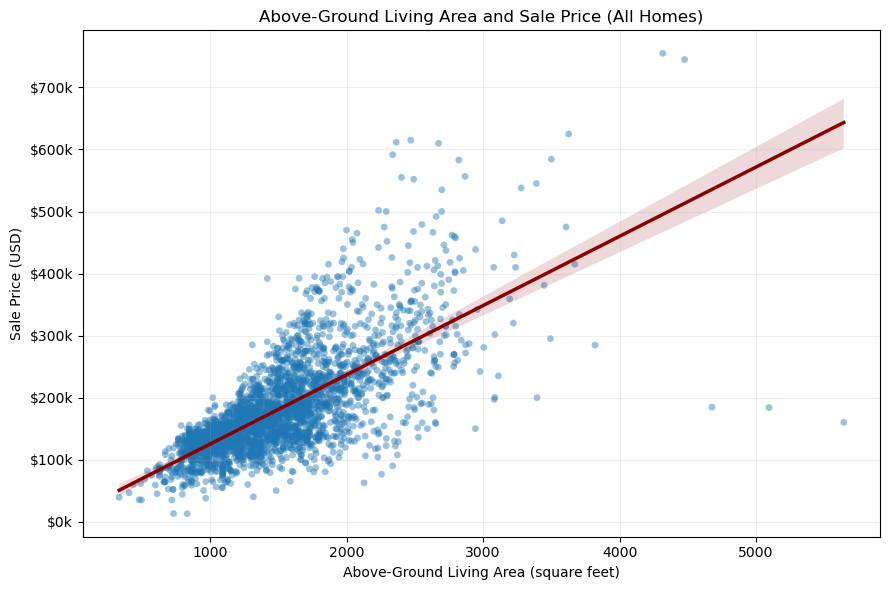

Saved chart to: /Users/lyndaknox/Downloads/DSA 8670/Codex CLI Hands-On/analysis/living_area_sale_price_all_homes.png


In [7]:
from matplotlib.ticker import FuncFormatter

currency_axis = FuncFormatter(lambda value, position: f'${value / 1000:,.0f}k')
plt.figure(figsize=(9, 6))
sns.regplot(
    data=cleaned_data, x='Gr Liv Area', y='SalePrice',
    scatter_kws={'alpha': 0.45, 's': 24, 'edgecolor': 'none'},
    line_kws={'color': 'darkred', 'linewidth': 2.5},
)
plt.title('Above-Ground Living Area and Sale Price (All Homes)')
plt.xlabel('Above-Ground Living Area (square feet)')
plt.ylabel('Sale Price (USD)')
plt.gca().yaxis.set_major_formatter(currency_axis)
plt.grid(alpha=0.2)
plt.tight_layout()
overall_plot_path = repo_root / 'analysis' / 'living_area_sale_price_all_homes.png'
plt.savefig(overall_plot_path, dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved chart to: {overall_plot_path}')

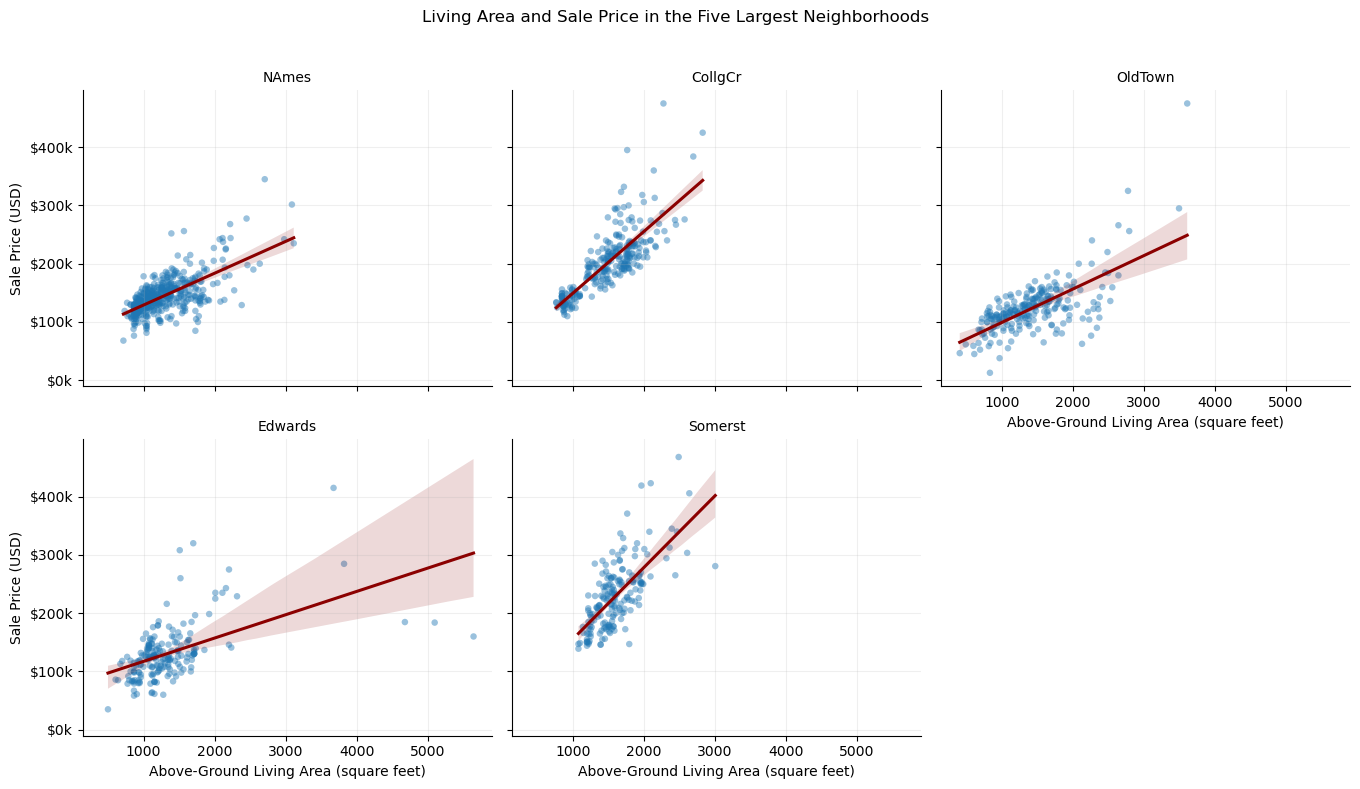

Neighborhoods shown: ['NAmes', 'CollgCr', 'OldTown', 'Edwards', 'Somerst']
Saved chart to: /Users/lyndaknox/Downloads/DSA 8670/Codex CLI Hands-On/analysis/living_area_sale_price_top_neighborhoods.png


In [8]:
top_neighborhoods = cleaned_data['Neighborhood'].value_counts().head(5).index.tolist()
top_five_data = cleaned_data[cleaned_data['Neighborhood'].isin(top_neighborhoods)].copy()

facet = sns.lmplot(
    data=top_five_data, x='Gr Liv Area', y='SalePrice',
    col='Neighborhood', col_order=top_neighborhoods, col_wrap=3,
    height=4, aspect=1.15,
    facet_kws={'sharex': True, 'sharey': True},
    scatter_kws={'alpha': 0.45, 's': 22, 'edgecolor': 'none'},
    line_kws={'color': 'darkred', 'linewidth': 2.2},
)
facet.set_titles('{col_name}')
facet.set_axis_labels('Above-Ground Living Area (square feet)', 'Sale Price (USD)')
for axis in facet.axes.flat:
    axis.yaxis.set_major_formatter(currency_axis)
    axis.grid(alpha=0.2)
facet.fig.subplots_adjust(top=0.88)
facet.fig.suptitle('Living Area and Sale Price in the Five Largest Neighborhoods')
neighborhood_plot_path = repo_root / 'analysis' / 'living_area_sale_price_top_neighborhoods.png'
facet.savefig(neighborhood_plot_path, dpi=200, bbox_inches='tight')
plt.show()
print('Neighborhoods shown:', top_neighborhoods)
print(f'Saved chart to: {neighborhood_plot_path}')

In [9]:
correlation_rows = [{'Neighborhood': 'All homes', 'house_count': len(cleaned_data), 'pearson_r': cleaned_data['Gr Liv Area'].corr(cleaned_data['SalePrice'])}]
for neighborhood in top_neighborhoods:
    subset = cleaned_data.loc[cleaned_data['Neighborhood'] == neighborhood]
    correlation_rows.append({
        'Neighborhood': neighborhood,
        'house_count': len(subset),
        'pearson_r': subset['Gr Liv Area'].corr(subset['SalePrice']),
    })
correlations = pd.DataFrame(correlation_rows).set_index('Neighborhood')
display(correlations.round({'pearson_r': 3}))

,house_count,pearson_r
Neighborhood,,
All homes,2930,0.707
NAmes,443,0.659
CollgCr,267,0.800
OldTown,239,0.677
Edwards,194,0.528
Somerst,182,0.683


### Initial interpretation

The association is positive overall: homes with more above-ground living area tend to have higher sale prices in this dataset. The overall Pearson correlation is **0.707**. It is also positive in each of the five largest neighborhoods, but the strength varies: **CollgCr** has the strongest correlation (**0.800**) and **Edwards** the weakest (**0.528**) among these five. The scatter panels show how the fitted lines and spread compare on common axes; correlation alone does not capture curvature or every difference in the relationship.

The largest living areas and sale prices appear far from the densest part of the overall point cloud. Such extreme points may influence an ordinary least-squares trend line, especially when they have unusually large x-values. The charts and correlations include every observation; no values were removed.